In [1]:
!pip install -q numpy==2.4.4 2>/dev/null
!pip install -q onnx==1.21.0 2>/dev/null
!pip install -q onnxruntime==1.24.4 2>/dev/null
!pip install -q onnx-tool==1.0.1 2>/dev/null

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 75.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 79.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 71.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 1.7 MB/s eta 0:00:00


This starter notebook for the [2026 NeuroGolf Championship](https://www.kaggle.com/competitions/neurogolf-2026) is designed to help contestants verify the functional correctness of their networks.  It allows one to load example pairs for a task, visualize them, and test whether a candidate network produces expected results across all public competition benchmarks.

## Enter a task number (between 1 and 400):

In [2]:
task_num = 3  # Task 0 is just an illustrative example (and not eligible for points)

## Color legend

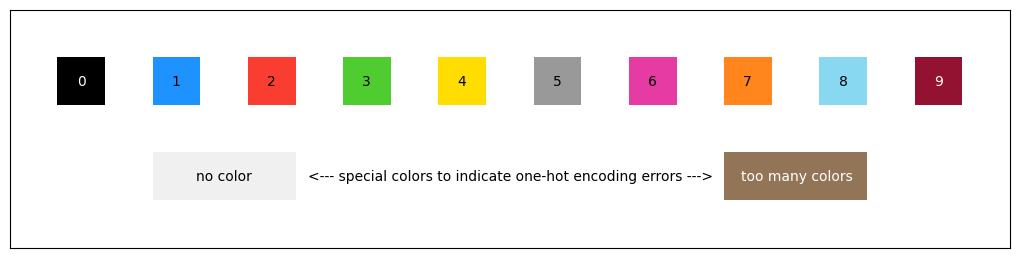

In [3]:
import sys
sys.path.append("/kaggle/input/competitions/neurogolf-2026/neurogolf_utils")
from neurogolf_utils import *
show_legend()

## Example <input, output> pairs

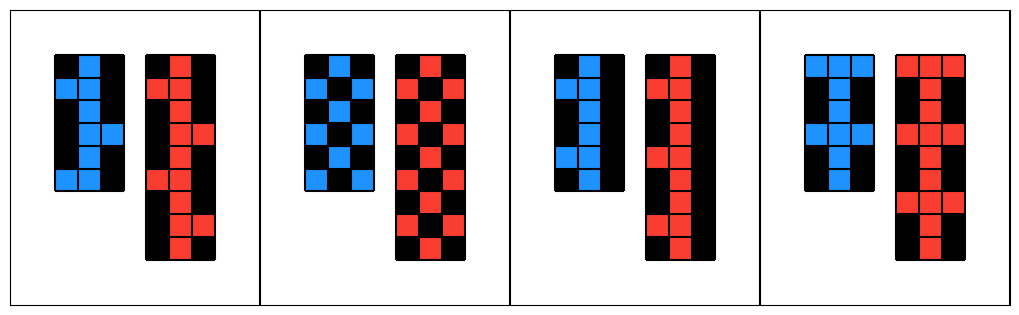

In [4]:
examples = load_examples(task_num)
show_examples(examples['train'] + examples['test'])

## Define your network to solve the task

The code below uses a utility we've provided to help you create [single-layer convolutional networks](https://en.wikipedia.org/wiki/Convolutional_layer).  It may be possible to solve other tasks in a similar way, but most will require more complicated architectures!

In [ ]:
def weight(channel_out, channel_in, kernel_coord):
  if kernel_coord == ( 0,  0) and channel_in == channel_out: return 1.0
  if kernel_coord == ( 0,  0) and channel_in != 5 and channel_out == 0: return -1.0
  if kernel_coord == (-1, -1) and channel_in != 5 and channel_out == 0: return 1.0
  if kernel_coord == (-1, -1) and channel_in != 5 and channel_out == 5: return -1.0
  return 0.0

network = single_layer_conv2d_network(weight, kernel_size=3)

In [5]:
import numpy as np
import onnx
import onnxruntime
from onnx import helper, TensorProto


def task003_network():

    #
    # Inputs / Outputs
    #

    x = helper.make_tensor_value_info(
        "input",
        TensorProto.FLOAT,
        [1,10,30,30]
    )

    #
    # Temporary output for debugging
    #

    y = helper.make_tensor_value_info(
        "output",
        TensorProto.FLOAT,
        [1,10,30,30]
    )

    inits = []

    def const(name, arr, dtype=np.int64):
        arr = np.asarray(arr, dtype=dtype)
        inits.append(
            onnx.numpy_helper.from_array(arr, name)
        )

    #
    # Slice constants
    #

    const("slice_starts", [0,0,0,0])
    const("slice_ends",   [1,10,6,3])
    const("slice_axes",   [0,1,2,3])
    const("slice_steps",  [1,1,1,1])

    #
    # Slice foreground channels (1..9)
    #

    const("fg_starts", [0,1,0,0])
    const("fg_ends",   [1,10,6,3])
    const("fg_axes",   [0,1,2,3])
    const("fg_steps",  [1,1,1,1])

    #
    # Constant 2
    #

    const(
        "two",
        np.array([2], dtype=np.float32),
        np.float32
    )

    #
    # top3 = rows 0..2
    #

    const("top_starts",[0,0,0,0])
    const("top_ends",[1,1,3,3])
    const("top_axes",[0,1,2,3])
    const("top_steps",[1,1,1,1])

    #
    # mid3 = rows 2..4
    #

    const("mid_starts",[0,0,2,0])
    const("mid_ends",[1,1,5,3])
    const("mid_axes",[0,1,2,3])
    const("mid_steps",[1,1,1,1])

    #
    # row1
    #

    const("row1_starts",[0,0,1,0])
    const("row1_ends",[1,1,2,3])
    const("row1_axes",[0,1,2,3])
    const("row1_steps",[1,1,1,1])

    #
    # row4
    #

    const("row4_starts",[0,0,4,0])
    const("row4_ends",[1,1,5,3])
    const("row4_axes",[0,1,2,3])
    const("row4_steps",[1,1,1,1])

    const(
        "one",
        np.array([1.0], dtype=np.float32),
        np.float32
    )

    const(
        "zero1",
        np.zeros((1,1,9,3),dtype=np.float32),
        np.float32
    )

    const(
        "zero7",
        np.zeros((1,7,9,3),dtype=np.float32),
        np.float32
    )
    
    const(
        "zero_i",
        np.array([0], dtype=np.int64),
        np.int64
    )

    const(
        "one_i",
        np.array([1], dtype=np.int64),
        np.int64
    )

    nodes = [

        #
        # Extract 6x3 patch
        #

        helper.make_node(
            "Slice",
            [
                "input",
                "slice_starts",
                "slice_ends",
                "slice_axes",
                "slice_steps"
            ],
            ["patch"]
        ),

        #
        # Keep channels 1..9
        #

        helper.make_node(
            "Slice",
            [
                "patch",
                "fg_starts",
                "fg_ends",
                "fg_axes",
                "fg_steps"
            ],
            ["foreground"]
        ),

        #
        # Collapse colors into binary image
        #

        helper.make_node(
            "ReduceMax",
            ["foreground"],
            ["img"],
            axes=[1],
            keepdims=1
        ),

        #
        # Convert 1 -> 2
        #

        helper.make_node(
            "Mul",
            ["img", "two"],
            ["img2"]
        ),

        helper.make_node(
            "Slice",
            [
            "img2",
            "top_starts",
            "top_ends",
            "top_axes",
            "top_steps"
            ],
            ["top3"]
        ),

        helper.make_node(
            "Slice",
            [
            "img2",
            "mid_starts",
            "mid_ends",
            "mid_axes",
            "mid_steps"
            ],
            ["mid3"]
        ),

        helper.make_node(
            "Slice",
            [
            "img2",
            "row1_starts",
            "row1_ends",
            "row1_axes",
            "row1_steps"
            ],
            ["row1"]
        ),

        helper.make_node(
            "Slice",
            [
            "img2",
            "row4_starts",
            "row4_ends",
            "row4_axes",
            "row4_steps"
            ],
            ["row4"]
        ),

        #
        # Cast row1 -> INT64
        #

        helper.make_node(
            "Cast",
            ["row1"],
            ["row1_i"],
            to=TensorProto.INT64
        ),

        #
        # Cast row4 -> INT64
        #

        helper.make_node(
            "Cast",
            ["row4"],
            ["row4_i"],
            to=TensorProto.INT64
        ),

        #
        # Compare rows
        #

        helper.make_node(
            "Equal",
            ["row1_i", "row4_i"],
            ["rows_equal_bool"]
        ),

        #
        # bool -> int64
        #

        helper.make_node(
            "Cast",
            ["rows_equal_bool"],
            ["rows_equal"],
            to=TensorProto.INT64
        ),

        #
        # all three entries equal?
        #

        helper.make_node(
            "ReduceMin",
            ["rows_equal"],
            ["rows_min"],
            axes=[3],
            keepdims=0
        ),

        #
        # rows_are_equal = rows_min == 1
        #

        helper.make_node(
            "Equal",
            ["rows_min", "one_i"],
            ["rows_are_equal"]
        ),

        #
        # Choose the correct tail
        #

        helper.make_node(
            "Where",
            [
                "rows_are_equal",
                "top3",
                "mid3"
            ],
            ["tail"]
        ),

        helper.make_node(
            "Concat",
            ["img2", "tail"],
            ["final9"],
            axis=2
        ),
        helper.make_node(
            "Div",
            ["final9","two"],
            ["fg"]
        ),

        helper.make_node(
            "Sub",
            ["one","fg"],
            ["bg"]
        ),

        helper.make_node(
            "Concat",
            [
                "bg",
                "zero1",
                "fg",
                "zero7"
            ],
            ["small_output"],
            axis=1
        ),

        helper.make_node(
            "Pad",
            ["small_output"],
            ["output"],
            mode="constant",
            pads=[0,0,0,0,0,0,21,27],
            value=0.0
        ),
    ]
    
    graph = helper.make_graph(
        nodes,
        "task003",
        [x],
        [y],
        inits
    )

    # graph.output.extend([
        # helper.make_tensor_value_info("img2", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("top3", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("mid3", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("row1", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("row4", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("rows_equal", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("all_equal", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("use_mid", TensorProto.FLOAT, None),    
        # helper.make_tensor_value_info("final9", TensorProto.FLOAT, None),
        # helper.make_tensor_value_info("bg", TensorProto.FLOAT, None),
    # ])

    model = helper.make_model(
        graph,
        ir_version=10,
        opset_imports=[
            helper.make_opsetid("", 10)
        ]
    )

    return model


#
# Build model
#

network = task003_network()

onnx.save(network, "task003.onnx")

In [16]:
#
# Test
#

session = onnxruntime.InferenceSession("task003.onnx")

bench = convert_to_numpy(examples["train"][0])

inp = bench["input"]

outs = session.run(None, {"input": inp})

# rows_equal = outs[-3]
# all_equal  = outs[-2]
# use_mid    = outs[-1]

# print(rows_equal)
# print(all_equal)
# print(use_mid)

bg = session.run(
    None,
    {"input": inp}
)[0]          # or [0] depending on outputs

# print(final9[0,0])
print(np.unique(bg))

[0. 1.]


2026-07-05 02:20:57.466766000 [W:onnxruntime:, graph.cc:122 MergeShapeInfo] Error merging shape info for output. 'bg' source:{1,1,9,3} target:{1,10,30,30}. Falling back to lenient merge.
2026-07-05 02:20:57.466808368 [W:onnxruntime:, graph.cc:5241 CleanUnusedInitializersAndNodeArgs] Removing initializer 'zero_i'. It is not used by any node and should be removed from the model.


## Verify your network

In [6]:
verify_network(network, task_num, examples)


2026-07-05 04:49:54.225791345 [W:onnxruntime:, graph.cc:5241 CleanUnusedInitializersAndNodeArgs] Removing initializer 'safe_name_28'. It is not used by any node and should be removed from the model.


Results on ARC-AGI examples: 4 pass, 0 fail
Results on ARC-GEN examples: 261 pass, 0 fail

Your network IS READY for submission!

Performance stats (memory values reported here are approximate):
Name          Type         Forward_MACs  FPercent      Memory  MPercent      Params  PPercent    InShape    OutShape
------------  ---------  --------------  ----------  --------  ----------  --------  ----------  ---------  ----------
Where_14      Where                   0  0.00%             36  8.49%              0  0.00%       1x1x1      1x1x3x3
Div_16        Div                   108  33.54%           112  26.42%             1  33.33%      1x1x9x3    1x1x9x3
Mul_3         Mul                    18  5.59%             72  16.98%             0  0.00%       1x1x6x3    1x1x6x3
Equal_13      Equal                   1  0.31%              9  2.12%              1  33.33%      1x1x1      1x1x1
ReduceMax_2   ReduceMax             162  50.31%            72  16.98%             0  0.00%       1x9x6x3   

/kaggle/working/task003.onnx